# TA-03 — Pelatihan dan Evaluasi Model Logistic Regression
## Tahap 3: Prediksi risiko gagal bayar kartu kredit

Notebook ini melatih dan membandingkan dua model:
1. Logistic Regression baseline.
2. Logistic Regression dengan `class_weight='balanced'`.

Dataset: `UCI_Credit_Card.csv`

Target: `default.payment.next.month`
- `0` = tidak gagal bayar
- `1` = gagal bayar

**Catatan:** preprocessing dilakukan dalam `Pipeline` dan hanya dipelajari dari data latih untuk menghindari data leakage. Letakkan file CSV di folder yang sama dengan notebook ini.

## 1. Import library dan membaca dataset

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    accuracy_score
)

sns.set_theme(style="whitegrid")

FILE_DATASET = Path("UCI_Credit_Card.csv")
if not FILE_DATASET.exists():
    raise FileNotFoundError(
        "UCI_Credit_Card.csv tidak ditemukan. Letakkan file CSV di folder yang sama dengan notebook."
    )

df = pd.read_csv(FILE_DATASET)
target = "default.payment.next.month"

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 2. Memisahkan fitur dan target

In [11]:
df_model = df.dropna(subset=[target]).copy()

X = df_model.drop(columns=["ID", target], errors="ignore")
y = df_model[target].astype(int)

print("Jumlah data:", len(X))
print("Jumlah fitur sebelum encoding:", X.shape[1])
print("\nDistribusi target:")
display(
    y.value_counts().sort_index()
    .rename(index={0: "Tidak gagal bayar", 1: "Gagal bayar"})
    .to_frame("Jumlah")
)

Jumlah data: 30000
Jumlah fitur sebelum encoding: 23

Distribusi target:


,Jumlah
default.payment.next.month,
Tidak gagal bayar,23364
Gagal bayar,6636


## 3. Membagi data latih dan data uji

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Data latih: {X_train.shape[0]:,} baris")
print(f"Data uji  : {X_test.shape[0]:,} baris")

Data latih: 24,000 baris
Data uji  : 6,000 baris


## 4. Menyiapkan preprocessing

Kolom demografi dan kode status pembayaran diperlakukan sebagai kategori. Kolom lain seperti usia, batas kredit, tagihan, dan pembayaran diperlakukan sebagai fitur numerik.

In [13]:
categorical_features = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"
]
categorical_features = [c for c in categorical_features if c in X.columns]
numeric_features = [c for c in X.columns if c not in categorical_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Fitur numerik:", len(numeric_features))
print("Fitur kategorikal:", len(categorical_features))

Fitur numerik: 14
Fitur kategorikal: 9


## 5. Melatih dua model Logistic Regression

In [14]:
models = {
    "Logistic Regression (Baseline)": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Logistic Regression (Balanced)": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}

for name, classifier in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model_pipeline.fit(X_train, y_train)
    trained_models[name] = model_pipeline
    print(f"{name}: selesai dilatih")

Logistic Regression (Baseline): selesai dilatih
Logistic Regression (Balanced): selesai dilatih


## 6. Evaluasi metrik kedua model

In [15]:
results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = (y_pred, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (kelas 1)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (kelas 1)": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score (kelas 1)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision (kelas 1),Recall (kelas 1),F1-Score (kelas 1),ROC-AUC
Model,,,,,
Logistic Regression (Baseline),0.8168,0.6615,0.3519,0.4594,0.7583
Logistic Regression (Balanced),0.7735,0.4893,0.5531,0.5193,0.7588


## 7. Confusion Matrix untuk setiap model

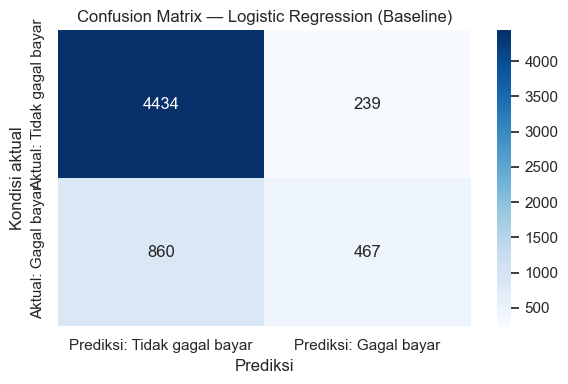

Classification report — Logistic Regression (Baseline)
                       precision    recall  f1-score   support

Tidak gagal bayar (0)       0.84      0.95      0.89      4673
      Gagal bayar (1)       0.66      0.35      0.46      1327

             accuracy                           0.82      6000
            macro avg       0.75      0.65      0.67      6000
         weighted avg       0.80      0.82      0.79      6000



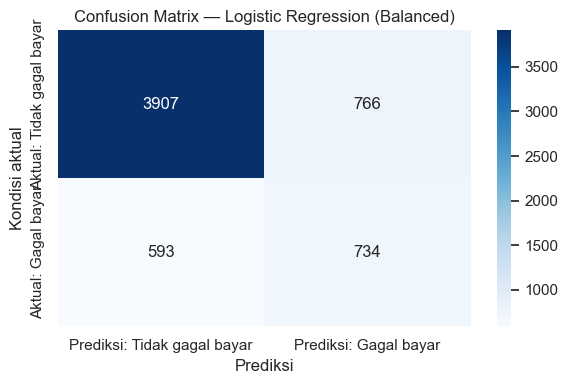

Classification report — Logistic Regression (Balanced)
                       precision    recall  f1-score   support

Tidak gagal bayar (0)       0.87      0.84      0.85      4673
      Gagal bayar (1)       0.49      0.55      0.52      1327

             accuracy                           0.77      6000
            macro avg       0.68      0.69      0.69      6000
         weighted avg       0.78      0.77      0.78      6000



In [16]:
for name, (y_pred, _) in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Prediksi: Tidak gagal bayar", "Prediksi: Gagal bayar"],
        yticklabels=["Aktual: Tidak gagal bayar", "Aktual: Gagal bayar"]
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Prediksi")
    plt.ylabel("Kondisi aktual")
    plt.tight_layout()
    plt.show()

    print(f"Classification report — {name}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Tidak gagal bayar (0)", "Gagal bayar (1)"],
        zero_division=0
    ))

## 8. Membandingkan kurva ROC

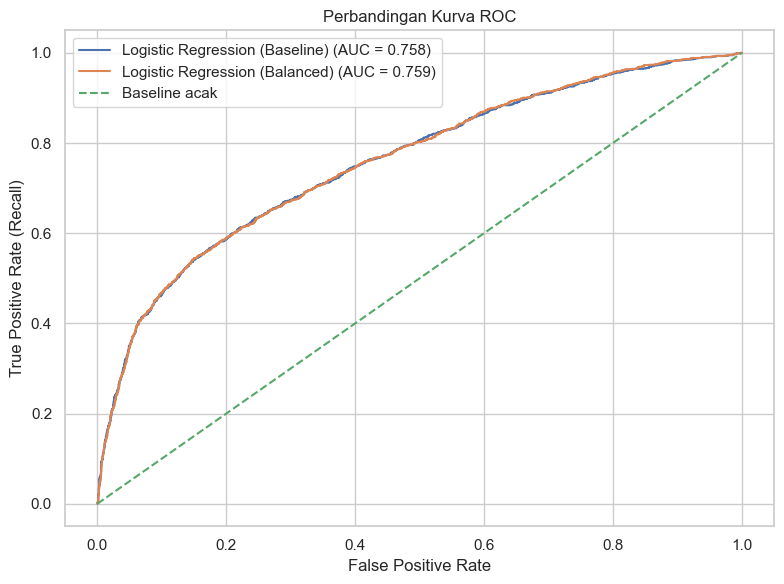

In [17]:
plt.figure(figsize=(8, 6))

for name, (_, y_prob) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Baseline acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Perbandingan Kurva ROC")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Memilih model sementara berdasarkan Recall dan F1-Score

Untuk kasus risiko gagal bayar, Recall kelas 1 penting karena mengukur seberapa banyak nasabah yang benar-benar gagal bayar berhasil terdeteksi. Namun, Recall tinggi dapat meningkatkan False Positive. Pertimbangkan juga Precision, F1-Score, ROC-AUC, dan kebutuhan bisnis.

In [18]:
display(
    results_df.sort_values(
        by=["Recall (kelas 1)", "F1-Score (kelas 1)", "ROC-AUC"],
        ascending=False
    ).round(4)
)

print("Gunakan hasil metrik dan confusion matrix untuk menentukan model yang paling sesuai.")
print("Jangan memilih model hanya berdasarkan Accuracy.")

,Accuracy,Precision (kelas 1),Recall (kelas 1),F1-Score (kelas 1),ROC-AUC
Model,,,,,
Logistic Regression (Balanced),0.7735,0.4893,0.5531,0.5193,0.7588
Logistic Regression (Baseline),0.8168,0.6615,0.3519,0.4594,0.7583


Gunakan hasil metrik dan confusion matrix untuk menentukan model yang paling sesuai.
Jangan memilih model hanya berdasarkan Accuracy.


In [19]:
# Memilih model berdasarkan Recall, F1-Score, dan ROC-AUC
best_model_name = (
    results_df
    .sort_values(
        by=["Recall (kelas 1)", "F1-Score (kelas 1)", "ROC-AUC"],
        ascending=False
    )
    .index[0]
)

best_model = trained_models[best_model_name]

# Menyimpan model beserta nama fitur yang digunakan
model_artifact = {
    "model": best_model,
    "feature_columns": list(X.columns),
    "target_column": target,
    "model_name": best_model_name
}

# Membuat folder models jika belum tersedia
Path("models").mkdir(exist_ok=True)

# Menyimpan model
joblib.dump(model_artifact, "models/credit_default_model.pkl")

print("Model berhasil disimpan!")
print("Model terpilih:", best_model_name)
print("File: models/credit_default_model.pkl")
print("Jumlah fitur:", len(X.columns))

Model berhasil disimpan!
Model terpilih: Logistic Regression (Balanced)
File: models/credit_default_model.pkl
Jumlah fitur: 23


## 10. Catatan hasil untuk laporan

Setelah menjalankan notebook, catat:
- Nilai Precision, Recall, F1-Score, dan ROC-AUC dari kedua model.
- Jumlah False Positive dan False Negative pada confusion matrix.
- Model mana yang lebih baik mendeteksi kelas gagal bayar.
- Alasan pemilihan model akhir berdasarkan kebutuhan manajemen risiko.

**Langkah berikutnya:** setelah memilih model berdasarkan hasil evaluasi, kita akan menyimpan keseluruhan pipeline menggunakan Joblib agar preprocessing dan model yang sama bisa dipakai di aplikasi Flask.